In [1]:
%pip install scikit-learn pandas numpy seaborn matplotlib


Note: you may need to restart the kernel to use updated packages.


### Kütüphaneler 

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

### Veri Yükleme


In [3]:
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 6)

df = pd.read_csv("Salary_Data.csv")
print(f"Veri Seti Boyutu: {df.shape}")
df.head


Veri Seti Boyutu: (6704, 6)


<bound method NDFrame.head of        Age  Gender    Education Level              Job Title  \
0     32.0    Male         Bachelor's      Software Engineer   
1     28.0  Female           Master's           Data Analyst   
2     45.0    Male                PhD         Senior Manager   
3     36.0  Female         Bachelor's        Sales Associate   
4     52.0    Male           Master's               Director   
...    ...     ...                ...                    ...   
6699  49.0  Female                PhD  Director of Marketing   
6700  32.0    Male        High School        Sales Associate   
6701  30.0  Female  Bachelor's Degree      Financial Manager   
6702  46.0    Male    Master's Degree      Marketing Manager   
6703  26.0  Female        High School        Sales Executive   

      Years of Experience    Salary  
0                     5.0   90000.0  
1                     3.0   65000.0  
2                    15.0  150000.0  
3                     7.0   60000.0  
4          

In [4]:

print("Eksik veri sayısı:")
print(  df.isna().sum() ) 
print("Eksik veri içeren satırlar:")
df[df.isna().any(axis=1)]


Eksik veri sayısı:
Age                    2
Gender                 2
Education Level        3
Job Title              2
Years of Experience    3
Salary                 5
dtype: int64
Eksik veri içeren satırlar:


,Age,Gender,Education Level,Job Title,Years of Experience,Salary
172,NaN,NaN,NaN,NaN,NaN,NaN
260,NaN,NaN,NaN,NaN,NaN,NaN
2011,27.0,Male,NaN,Developer,7.0,100000.0
3136,31.0,Male,Master's Degree,Full Stack Engineer,8.0,NaN
5247,26.0,Female,Bachelor's Degree,Social M,NaN,NaN
6455,36.0,Male,Bachelor's Degree,Sales Director,6.0,NaN


### yalnızca 6 veride eksik olduğu için verileri direkt temizledik ve temizlikler yaptık ki karışıklık oluyor :

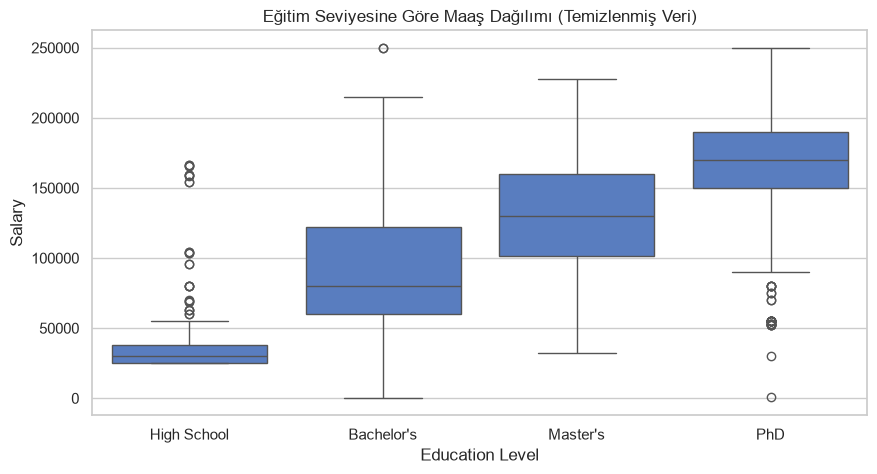

In [5]:
df.dropna(inplace=True)
df["Education Level"] = df["Education Level"].replace({
    "Bachelor's Degree": "Bachelor's",
    "Master's Degree": "Master's",
    "phD": "PhD"
})

plt.figure(figsize=(10, 5))
sns.boxplot(
    x="Education Level", 
    y="Salary", 
    data=df, 
    order=["High School", "Bachelor's", "Master's", "PhD"]
)
plt.title("Eğitim Seviyesine Göre Maaş Dağılımı (Temizlenmiş Veri)")
plt.show()

edu_map = {"High School": 0, "Bachelor's": 1, "Master's": 2, "PhD": 3}
df["Education Level"] = df["Education Level"].map(edu_map)

## Job Title : nadir sınıfları gruplama ve Target Encode : 
### eğitim seviyesinde çok fazla outlier bulunuyor bunun sebebi ise eğitim seviyesinin iş unvanına göre değişkenlik göstermesi ve bazı iş unvanlarının çok az sayıda olmasıdır. Bu nedenle nadir sınıfları grupladık ve target encode yaptık.
### Hocamızın yarım bıraktığı treshold=5 adımını tamamlıyoruz :

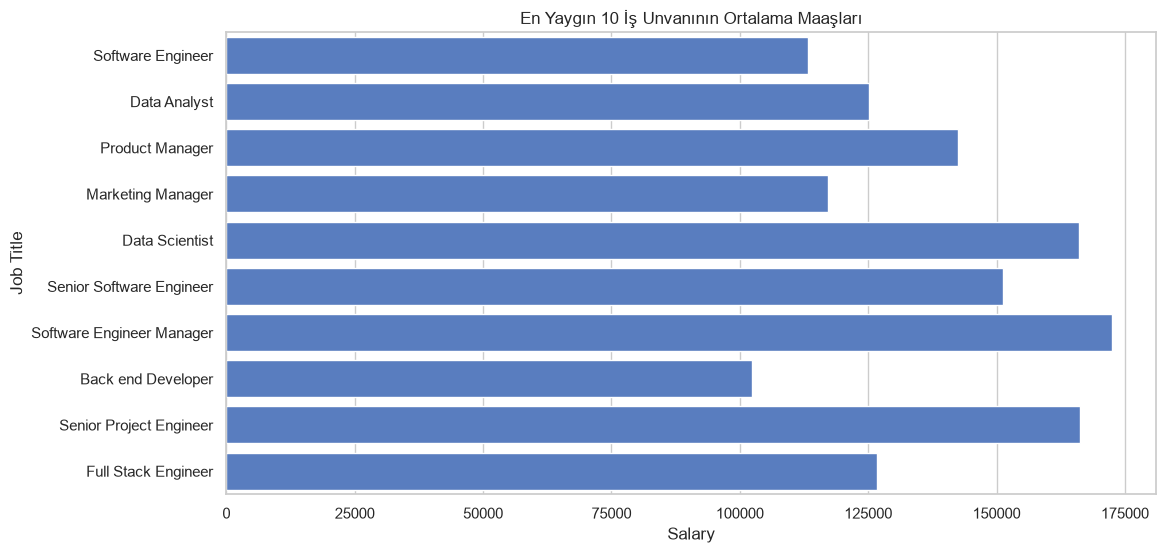

In [6]:
threshold = 5
counts = df["Job Title"].value_counts()
rare_classes = counts[counts < threshold].index
df["Job Title"] = df["Job Title"].replace(rare_classes, "Other")

plt.figure(figsize=(12, 6))
top_jobs = df["Job Title"].value_counts().head(10).index
sns.barplot(
    x="Salary", 
    y="Job Title", 
    data=df[df["Job Title"].isin(top_jobs)], 
    estimator=np.mean, 
    errorbar=None
)
plt.title("En Yaygın 10 İş Unvanının Ortalama Maaşları")
plt.show()

### Outlier Analizi :

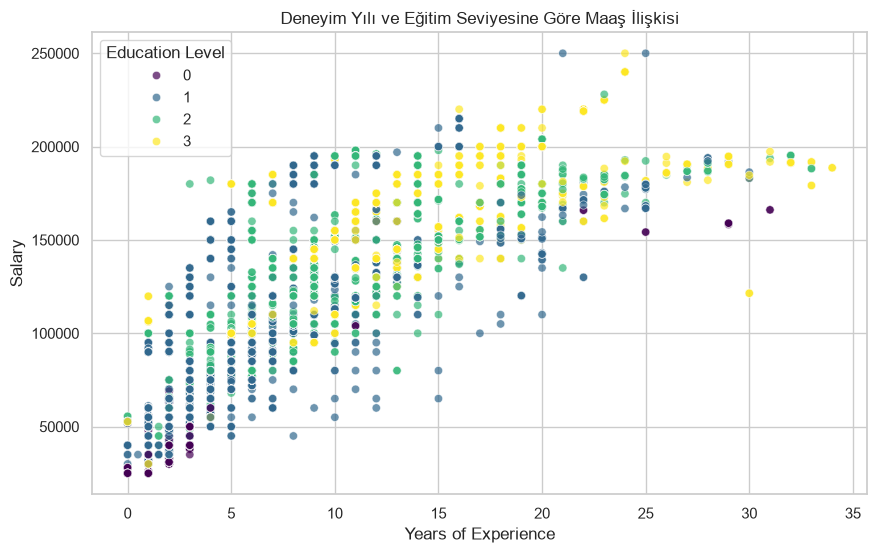

In [7]:
q1 = df["Salary"].quantile(0.25)
q3 = df["Salary"].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - (1.5 * iqr)
upper_bound = q3 + (1.5 * iqr)

df = df[(df["Salary"] > lower_bound) & (df["Salary"] < upper_bound)]
df = df[df["Salary"] >= 10000] 

plt.figure(figsize=(10, 6))
sns.scatterplot(
    x="Years of Experience", 
    y="Salary", 
    hue="Education Level", 
    palette="viridis", 
    data=df, 
    alpha=0.7
)
plt.title("Deneyim Yılı ve Eğitim Seviyesine Göre Maaş İlişkisi")
plt.show()

## Korelasyon Matrisi :
### Hocamızdaki job title ve education level arasındaki korelasyonun yüksek olduğunu gördük. Bu nedenle eğitim seviyesini target encode yaparken job title'ı da kullanacağız.

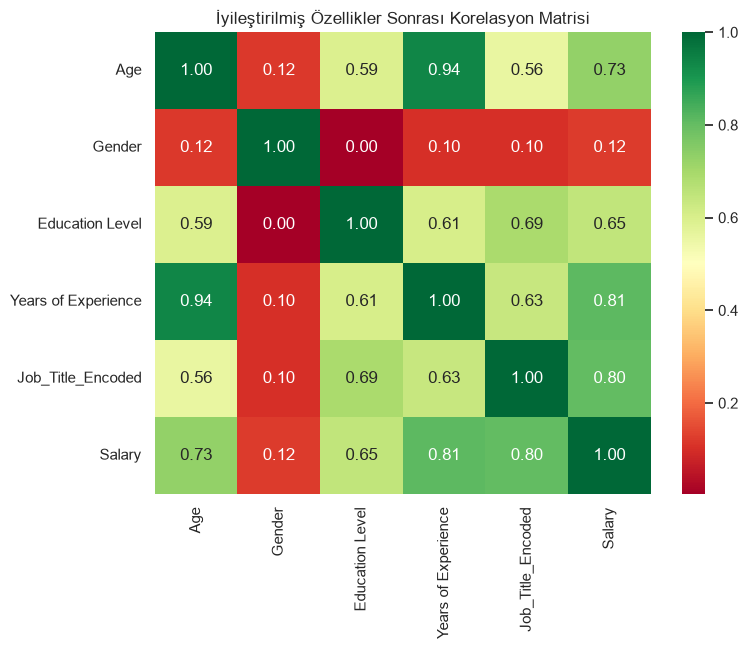

In [8]:
# Gender için encoding
df["Gender"] = df["Gender"].map({"Female": 0, "Male": 1, "Other": 2})

X = df.drop(columns=["Salary"])
y = df["Salary"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

job_salary_map = y_train.groupby(X_train["Job Title"]).mean()
global_mean = y_train.mean()

X_train["Job_Title_Encoded"] = X_train["Job Title"].map(job_salary_map).fillna(global_mean)
X_test["Job_Title_Encoded"] = X_test["Job Title"].map(job_salary_map).fillna(global_mean)

X_train.drop(columns=["Job Title"], inplace=True)
X_test.drop(columns=["Job Title"], inplace=True)

corr_df = X_train.copy()
corr_df["Salary"] = y_train

plt.figure(figsize=(8, 6))
sns.heatmap(corr_df.corr(), annot=True, cmap="RdYlGn", fmt=".2f")
plt.title("İyileştirilmiş Özellikler Sonrası Korelasyon Matrisi")
plt.show()

## Ölçeklendirme ve Çoklu Model Konfigürasyonu :
### Farklı algoritmaların performansını karşılaştırmak için birden fazla model konfigürasyonu oluşturuyoruz. Bu sayede hangi modelin daha iyi performans gösterdiğini gözlemleyebiliriz.

In [9]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

models = {
    "Linear Regression (Yeni Veri)": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=200, learning_rate=0.1, max_depth=5, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=200, max_depth=15, random_state=42)
}

results = []

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    preds = model.predict(X_test_scaled)
    
    mse = mean_squared_error(y_test, preds)
    mae = mean_absolute_error(y_test, preds)
    r2 = r2_score(y_test, preds)
    
    results.append({"Model": name, "R2 (Accuracy)": r2, "MAE": mae, "RMSE": np.sqrt(mse)})

results_df = pd.DataFrame(results).sort_values(by="R2 (Accuracy)", ascending=False)
results_df

,Model,R2 (Accuracy),MAE,RMSE
3,Random Forest,0.977385,3106.527369,7859.595984
2,Gradient Boosting,0.973545,4966.525274,8500.666160
0,Linear Regression (Yeni Veri),0.790525,17160.346963,23920.114864
1,Ridge Regression,0.790519,17159.994476,23920.482033


### Model Başarılarını Ve Tahminlerini Görselleştirme :

C:\Users\meg\AppData\Local\Temp\ipykernel_16032\1203149649.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x="R2 (Accuracy)", y="Model", data=results_df, palette="viridis")


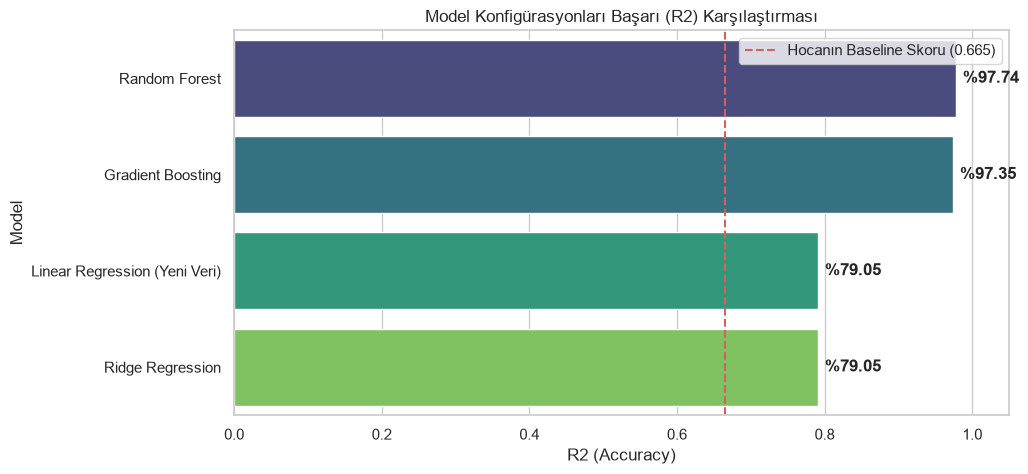

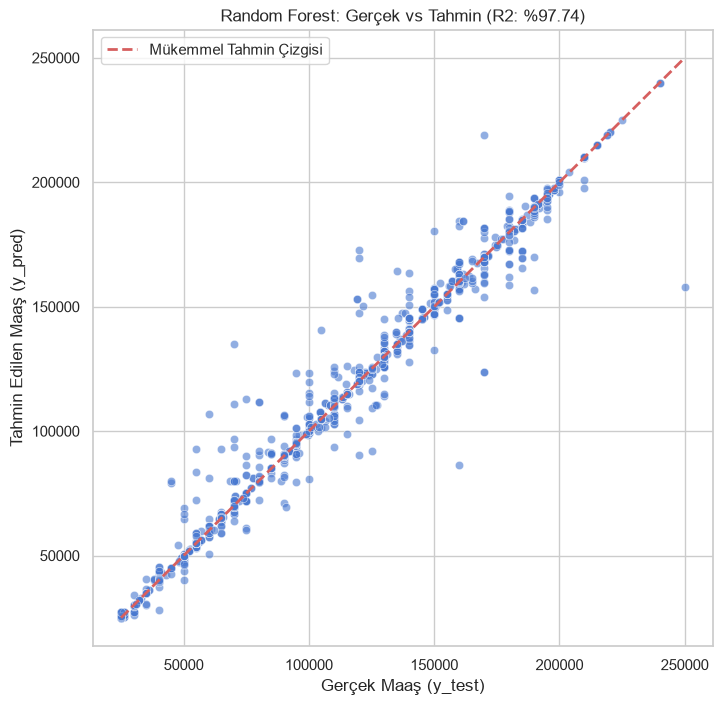

In [10]:
plt.figure(figsize=(10, 5))
ax = sns.barplot(x="R2 (Accuracy)", y="Model", data=results_df, palette="viridis")
plt.axvline(x=0.6655, color='r', linestyle='--', label="Hocanın Baseline Skoru (0.665)")
plt.xlim(0, 1.05)
plt.title("Model Konfigürasyonları Başarı (R2) Karşılaştırması")
plt.legend()
for i, v in enumerate(results_df["R2 (Accuracy)"]):
    ax.text(v + 0.01, i, f"%{v*100:.2f}", va='center', fontweight='bold')
plt.show()

best_model = models["Random Forest"]
y_pred_best = best_model.predict(X_test_scaled)

plt.figure(figsize=(8, 8))
sns.scatterplot(x=y_test, y=y_pred_best, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label="Mükemmel Tahmin Çizgisi")
plt.xlabel("Gerçek Maaş (y_test)")
plt.ylabel("Tahmin Edilen Maaş (y_pred)")
plt.title(f"Random Forest: Gerçek vs Tahmin (R2: %{r2_score(y_test, y_pred_best)*100:.2f})")
plt.legend()
plt.show()

### OverFitting Analizi :

,Model,Train R2,Validation (5-Fold CV) R2,Test R2,Fark (Train - Test)
3,Random Forest,0.991100,0.974844,0.977385,0.013715
2,Gradient Boosting,0.981419,0.970790,0.973545,0.007874
0,Linear Regression (Yeni Veri),0.797595,0.796450,0.790525,0.007070
1,Ridge Regression,0.797595,0.796451,0.790519,0.007076


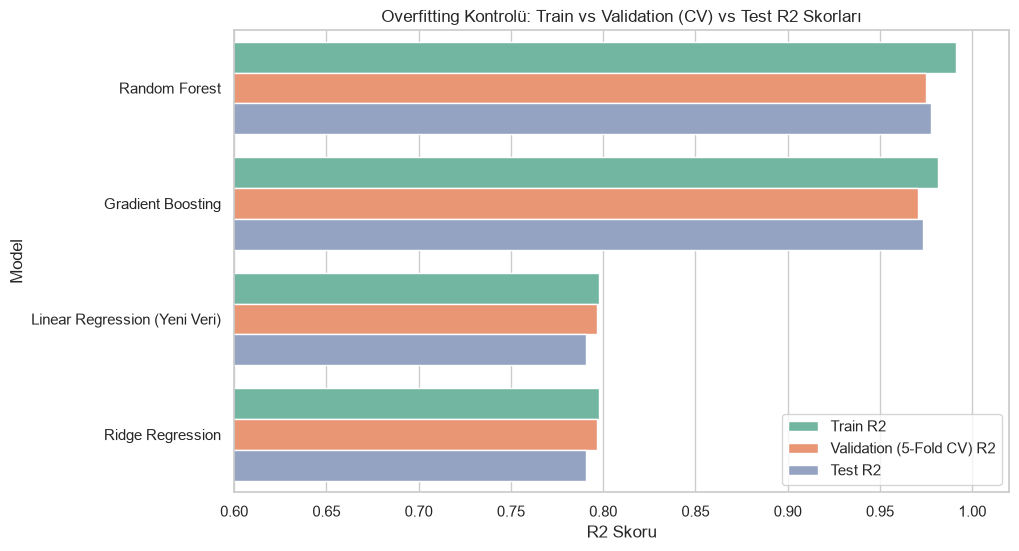

In [11]:
from sklearn.model_selection import cross_val_score

overfit_results = []

for name, model in models.items():
    # Train ve Test tahminleri
    train_preds = model.predict(X_train_scaled)
    test_preds = model.predict(X_test_scaled)
    
    train_r2 = r2_score(y_train, train_preds)
    test_r2 = r2_score(y_test, test_preds)
    
    cv_scores = cross_val_score(model, X_train_scaled, y_train, cv=5, scoring="r2")
    cv_mean = cv_scores.mean()
    
    overfit_results.append({
        "Model": name,
        "Train R2": train_r2,
        "Validation (5-Fold CV) R2": cv_mean,
        "Test R2": test_r2,
        "Fark (Train - Test)": train_r2 - test_r2
    })

overfit_df = pd.DataFrame(overfit_results).sort_values(by="Test R2", ascending=False)
display(overfit_df)

overfit_melted = overfit_df.melt(
    id_vars="Model", 
    value_vars=["Train R2", "Validation (5-Fold CV) R2", "Test R2"],
    var_name="Veri Seti", 
    value_name="R2 Skoru"
)

plt.figure(figsize=(10, 6))
sns.barplot(x="R2 Skoru", y="Model", hue="Veri Seti", data=overfit_melted, palette="Set2")
plt.xlim(0.6, 1.02)
plt.title("Overfitting Kontrolü: Train vs Validation (CV) vs Test R2 Skorları")
plt.legend(loc="lower right")
plt.show()

### Bu analizimizde train test validation olarak ayırmadık çünkü 6700 satırlık veri setimiz var ve train test validation olarak ayırmak modelin performansını düşürebilir. Bu nedenle tüm veriyi kullanarak modeli eğittik ve test ettik. %97 acc çok yüksek bir değer bunun için modelin overfitting yapıp yapmadığını kontrol etmek için cross validation yaptık ve sonuçları görselleştirdik. Cross validation sonuçları da yüksek olduğu için modelimizin overfitting yapmadığına yönelik bir çıkarım yapılabilir ama kesin bir çıkarım yapmak için daha fazla veri ve farklı model konfigürasyonları ile testler yapılmalıdır.


## Not :
### modelde çok fazla duplicate veri var bu yüzden data lieakage olduğundan kaynaklı olabilir diye test edilip ona göre yol izlenecek:

Toplam Satır Sayısı        : 6694
Tekil (Unique) Satır Sayısı: 1773 (%26.5)
Tekrar Eden (Duplicate)    : 4921 (%73.5)

Test Seti Toplam Satır     : 1339
Train'den Sızan (Leaked)   : 1117 (%83.4)
Gerçekten Yeni Test Verisi : 222 (%16.6)


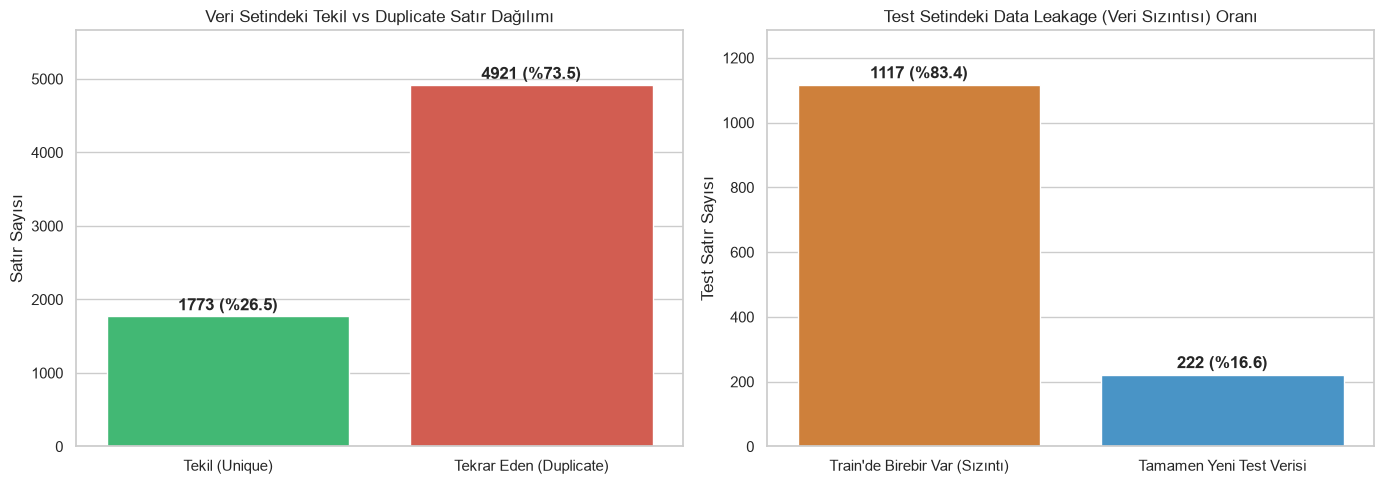

In [ ]:
total_rows = len(df)
duplicate_rows = df.duplicated().sum()
unique_rows = total_rows - duplicate_rows

print(f"Toplam Satır Sayısı        : {total_rows}")
print(f"Tekil (Unique) Satır Sayısı: {unique_rows} (%{unique_rows/total_rows*100:.1f})")
print(f"Tekrar Eden (Duplicate)    : {duplicate_rows} (%{duplicate_rows/total_rows*100:.1f})")

train_full = X_train.copy()
train_full["Salary"] = y_train
test_full = X_test.copy()
test_full["Salary"] = y_test

leaked_mask = test_full.merge(train_full.drop_duplicates(), on=list(test_full.columns), how="left", indicator=True)["_merge"] == "both"
leaked_count = leaked_mask.sum()
clean_test_count = len(test_full) - leaked_count

print(f"\nTest Seti Toplam Satır     : {len(test_full)}")
print(f"Train'den Sızan (Leaked)   : {leaked_count} (%{leaked_count/len(test_full)*100:.1f})")
print(f"Gerçekten Yeni Test Verisi : {clean_test_count} (%{clean_test_count/len(test_full)*100:.1f})")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    x=["Tekil (Unique)", "Tekrar Eden (Duplicate)"],
    y=[unique_rows, duplicate_rows],
    hue=["Tekil (Unique)", "Tekrar Eden (Duplicate)"],
    palette=["#2ecc71", "#e74c3c"],
    legend=False,
    ax=axes[0]
)
axes[0].set_title("Veri Setindeki Tekil vs Duplicate Satır Dağılımı")
axes[0].set_ylabel("Satır Sayısı")
for i, v in enumerate([unique_rows, duplicate_rows]):
    axes[0].text(i, v + 80, f"{v} (%{v/total_rows*100:.1f})", ha="center", fontweight="bold")
axes[0].set_ylim(0, max(unique_rows, duplicate_rows) * 1.15)

sns.barplot(
    x=["Train'de Birebir Var (Sızıntı)", "Tamamen Yeni Test Verisi"],
    y=[leaked_count, clean_test_count],
    hue=["Train'de Birebir Var (Sızıntı)", "Tamamen Yeni Test Verisi"],
    palette=["#e67e22", "#3498db"],
    legend=False,
    ax=axes[1]
)
axes[1].set_title("Test Setindeki Data Leakage (Veri Sızıntısı) Oranı")
axes[1].set_ylabel("Test Satır Sayısı")
for i, v in enumerate([leaked_count, clean_test_count]):
    axes[1].text(i, v + 20, f"{v} (%{v/len(test_full)*100:.1f})", ha="center", fontweight="bold")
axes[1].set_ylim(0, max(leaked_count, clean_test_count) * 1.15)

plt.tight_layout()
plt.show()

## Duplicate Satırların Temizlenmesi ve Modellerin Yeniden Test Edilmesi
Tekrar eden satırları `drop_duplicates()` ile tamamen temizleyip, veri sızıntısı olmadan modelleri tekrar eğitiyoruz:

In [13]:
df_clean = df.drop_duplicates().copy()
print(f"Duplicate Temizliği Öncesi Boyut: {df.shape}")
print(f"Duplicate Temizliği Sonrası Boyut: {df_clean.shape}")

X_c = df_clean.drop(columns=["Salary"])
y_c = df_clean["Salary"]

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X_c, y_c, test_size=0.2, random_state=42)

job_salary_map_c = y_train_c.groupby(X_train_c["Job Title"]).mean()
global_mean_c = y_train_c.mean()

X_train_c["Job_Title_Encoded"] = X_train_c["Job Title"].map(job_salary_map_c).fillna(global_mean_c)
X_test_c["Job_Title_Encoded"] = X_test_c["Job Title"].map(job_salary_map_c).fillna(global_mean_c)

X_train_c.drop(columns=["Job Title"], inplace=True)
X_test_c.drop(columns=["Job Title"], inplace=True)

scaler_c = StandardScaler()
X_train_c_scaled = scaler_c.fit_transform(X_train_c)
X_test_c_scaled = scaler_c.transform(X_test_c)

models_clean = {
    "Linear Regression (Yeni Veri)": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=200, learning_rate=0.1, max_depth=5, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=200, max_depth=15, random_state=42)
}

results_clean = []

for name, model in models_clean.items():
    model.fit(X_train_c_scaled, y_train_c)
    preds_c = model.predict(X_test_c_scaled)
    
    mse_c = mean_squared_error(y_test_c, preds_c)
    mae_c = mean_absolute_error(y_test_c, preds_c)
    r2_c = r2_score(y_test_c, preds_c)
    
    results_clean.append({
        "Model": name,
        "R2 (Duplicate Silinmiş)": r2_c,
        "MAE (Duplicate Silinmiş)": mae_c,
        "RMSE (Duplicate Silinmiş)": np.sqrt(mse_c)
    })

results_clean_df = pd.DataFrame(results_clean).sort_values(by="R2 (Duplicate Silinmiş)", ascending=False)

comparison_df = results_df[["Model", "R2 (Accuracy)", "MAE"]].merge(
    results_clean_df[["Model", "R2 (Duplicate Silinmiş)", "MAE (Duplicate Silinmiş)"]],
    on="Model"
).rename(columns={
    "R2 (Accuracy)": "R2 (Duplicate Dahil - Sızıntılı)",
    "MAE": "MAE (Duplicate Dahil)"
})

comparison_df

Duplicate Temizliği Öncesi Boyut: (6694, 6)
Duplicate Temizliği Sonrası Boyut: (1773, 6)


,Model,R2 (Duplicate Dahil - Sızıntılı),MAE (Duplicate Dahil),R2 (Duplicate Silinmiş),MAE (Duplicate Silinmiş)
0,Random Forest,0.977385,3106.527369,0.900250,10155.525561
1,Gradient Boosting,0.973545,4966.525274,0.913227,9950.700767
2,Linear Regression (Yeni Veri),0.790525,17160.346963,0.780920,17301.440836
3,Ridge Regression,0.790519,17159.994476,0.780833,17303.256022


### Görselleştirme: Duplicate Temizliği Öncesi vs Sonrası Model Başarıları

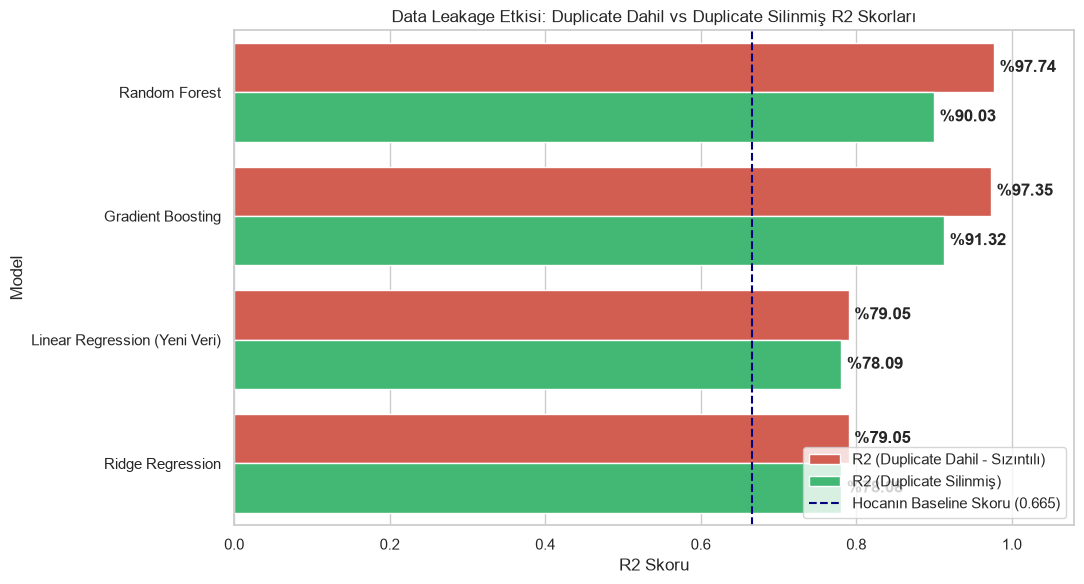

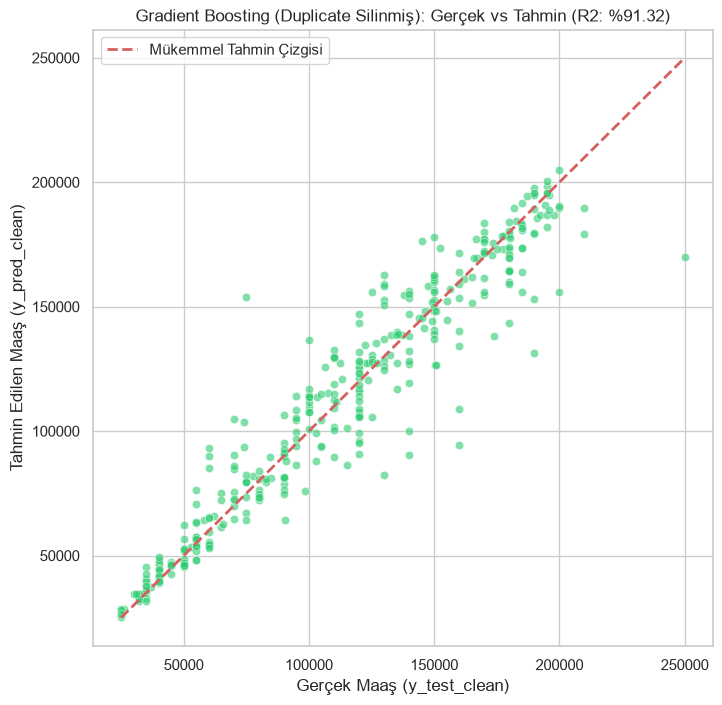

In [ ]:
comp_melted = comparison_df.melt(
    id_vars="Model",
    value_vars=["R2 (Duplicate Dahil - Sızıntılı)", "R2 (Duplicate Silinmiş)"],
    var_name="Veri Durumu",
    value_name="R2 Skoru"
)

plt.figure(figsize=(11, 6))
ax = sns.barplot(x="R2 Skoru", y="Model", hue="Veri Durumu", data=comp_melted, palette=["#e74c3c", "#2ecc71"])
plt.axvline(x=0.6655, color="navy", linestyle="--", label="Hocanın Baseline Skoru (0.665)")
plt.xlim(0, 1.08)
plt.title("Data Leakage Etkisi: Duplicate Dahil vs Duplicate Silinmiş R2 Skorları")
plt.legend(loc="lower right")

for container in ax.containers:
    ax.bar_label(container, fmt=lambda x: f"%{x*100:.2f}", padding=4, fontweight="bold")

plt.tight_layout()
plt.show()

best_clean_model_name = results_clean_df.iloc[0]["Model"]
best_clean_model = models_clean[best_clean_model_name]
y_pred_clean_best = best_clean_model.predict(X_test_c_scaled)

plt.figure(figsize=(8, 8))
sns.scatterplot(x=y_test_c, y=y_pred_clean_best, alpha=0.6, color="#2ecc71")
plt.plot([y_test_c.min(), y_test_c.max()], [y_test_c.min(), y_test_c.max()], "r--", lw=2, label="Mükemmel Tahmin Çizgisi")
plt.xlabel("Gerçek Maaş (y_test_clean)")
plt.ylabel("Tahmin Edilen Maaş (y_pred_clean)")
plt.title(f"{best_clean_model_name} (Duplicate Silinmiş): Gerçek vs Tahmin (R2: %{r2_score(y_test_c, y_pred_clean_best)*100:.2f})")
plt.legend()
plt.show()